# Monetary policy in HANK: the code behind the slides

This notebook computes the model figures of the monetary policy slides (lecture 11), in the same order. The model is the IKC model of the fiscal lectures with a real rate rule $r_t = r_{ss}+\epsilon^r_t$ and fixed debt $B=0.25$. Figures are saved in `figs/`.

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import HANKModel

## Settings

In [2]:
plt.rcParams.update({'axes.grid': True, 'grid.color': 'black', 'grid.alpha': 0.25, 'grid.linestyle': '--', 'font.size': 12, 'lines.linewidth': 2})
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

T_plot = 11 # years shown in the figures
rate_cut = -0.0025 # one-year rate cut in the forward guidance exercises

## 1. Model and steady state

`find_IRFs` gives the full solution for a 25 bp rate cut, used to check the hand-made solutions below.

In [3]:
model = HANKModel.HANKModelClass(name='baseline')
model.find_ss(do_print=True)
model.compute_jacs()
model.find_IRFs(shocks=['eps_r'])

par = model.par
ss = model.ss
T = par.T
I = np.eye(T)
Lag = np.eye(T,k=-1)
years = np.arange(T_plot)

dr = model.IRF['r']
dT = ss.B*Lag@dr

steady state found in 1.7 secs
 beta  =   0.9103
 tau   =   0.2050
 C     =   0.8000
Discrepancy in A =   0.00000000
Discrepancy in Y =   0.00000000


## 2. RANK

### Jacobians in closed form

$$
M_{t,s}=(1-\beta)\beta^{s},\qquad M_{t,s}^{r}=\underbrace{(1-\beta)\beta^{s+1}B}_{\text{interest income}}-\underbrace{\beta^{s+2}\frac{C}{\sigma}}_{\text{level}}+\underbrace{\mathbf{1}_{t>s}\,\beta\frac{C}{\sigma}}_{\text{tilt}}
$$

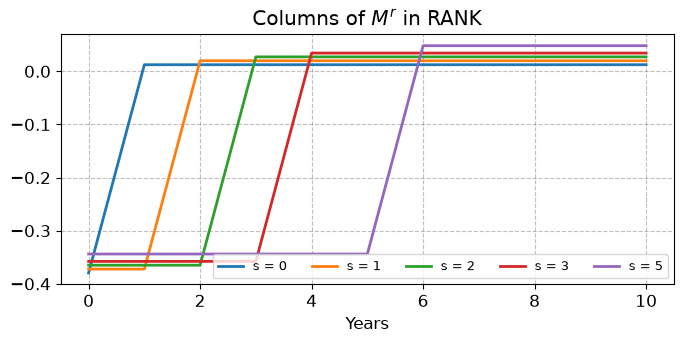

In [4]:
beta_RA = 1/(1+ss.r)
q = beta_RA**np.arange(T)
tilt = beta_RA*ss.C_hh/par.sigma

M_RA = (1-beta_RA)*np.outer(np.ones(T),q)
M_r_RA = np.outer(np.ones(T),(1-beta_RA)*beta_RA*q*ss.B - beta_RA*q*tilt)
M_r_RA += tilt*(np.arange(T)[:,None] > np.arange(T)[None,:])

fig, ax = plt.subplots(figsize=(7,3.6))
for s in [0,1,2,3,5]:
    ax.plot(years,M_r_RA[:T_plot,s],label=f's = {s}')
ax.set(xlabel='Years',title='Columns of $M^{r}$ in RANK')
ax.legend(ncol=5,fontsize=9)
fig.tight_layout()
fig.savefig('figs/mon_Mr_RANK.pdf')

### Euler equation

Iterating the Euler equation forward: $dC_t=-\beta\frac{C}{\sigma}\sum_{k\geq t}dr_k$.

In [5]:
def C_RANK(dr):
    """RANK consumption response from the iterated Euler equation."""

    return -tilt*np.cumsum(dr[::-1])[::-1]

dC_RA = C_RANK(dr)

### Direct and indirect effects

$d\boldsymbol{C}=\boldsymbol{M}^{r}d\boldsymbol{r}+\boldsymbol{M}\left(d\boldsymbol{Y}-d\boldsymbol{T}\right)$: direct plus indirect.

max |direct + indirect - total| = 2.2e-19
direct share of the impact response: 0.96


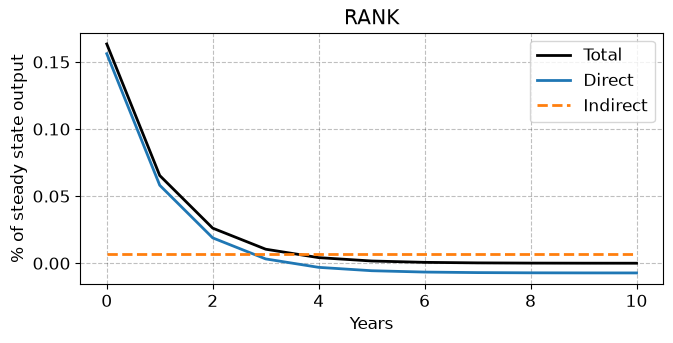

In [6]:
direct_RA = M_r_RA@dr
indirect_RA = M_RA@(dC_RA-dT)

print(f'max |direct + indirect - total| = {np.max(np.abs(direct_RA+indirect_RA-dC_RA)[:50]):.1e}')
print(f'direct share of the impact response: {direct_RA[0]/dC_RA[0]:.2f}')

fig, ax = plt.subplots(figsize=(7,3.6))
ax.plot(years,100*dC_RA[:T_plot],color='black',label='Total')
ax.plot(years,100*direct_RA[:T_plot],label='Direct')
ax.plot(years,100*indirect_RA[:T_plot],ls='--',label='Indirect')
ax.set(xlabel='Years',ylabel='% of steady state output',title='RANK')
ax.legend()
fig.tight_layout()
fig.savefig('figs/mon_decomp_RANK.pdf')

## 3. HANK

### Jacobians from GEModelTools

The household block takes the return paid at $t$, $r_{t-1}$, so $\boldsymbol{M}^{r}=\boldsymbol{J}^{ra}\boldsymbol{L}$.

iMPC at impact: RANK 0.020, HANK 0.357


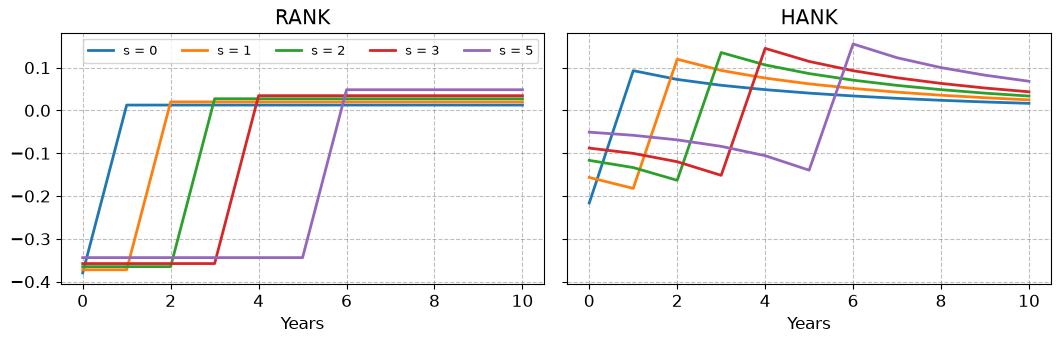

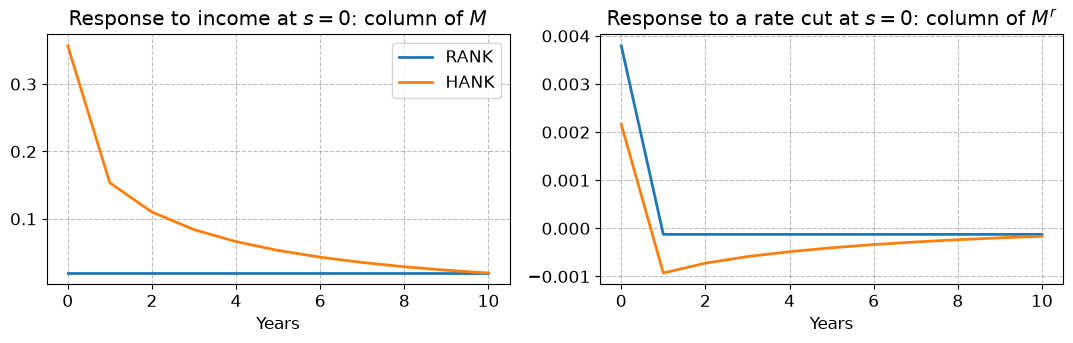

In [7]:
M = model.jac_hh[('C_hh','Z')]
M_r = model.jac_hh[('C_hh','ra')]@Lag

fig, axes = plt.subplots(1,2,figsize=(11,3.6),sharey=True)
for ax, Jacobian, title in zip(axes,[M_r_RA,M_r],['RANK','HANK']):
    for s in [0,1,2,3,5]:
        ax.plot(years,Jacobian[:T_plot,s],label=f's = {s}')
    ax.set(xlabel='Years',title=title)
axes[0].legend(ncol=5,fontsize=9)
fig.tight_layout()
fig.savefig('figs/mon_Mr_compare.pdf')

fig, axes = plt.subplots(1,2,figsize=(11,3.6))
axes[0].plot(years,M_RA[:T_plot,0],label='RANK')
axes[0].plot(years,M[:T_plot,0],label='HANK')
axes[0].set(xlabel='Years',title='Response to income at $s=0$: column of $M$')
axes[0].legend()
axes[1].plot(years,-0.01*M_r_RA[:T_plot,0],label='RANK')
axes[1].plot(years,-0.01*M_r[:T_plot,0],label='HANK')
axes[1].set(xlabel='Years',title='Response to a rate cut at $s=0$: column of $M^{r}$')
fig.tight_layout()
fig.savefig('figs/mon_M_vs_Mr.pdf')

print(f'iMPC at impact: RANK {M_RA[0,0]:.3f}, HANK {M[0,0]:.3f}')

### The monetary IKC

$$
d\boldsymbol{Y}=\left(\boldsymbol{I}-\boldsymbol{M}\right)^{-1}\left(\boldsymbol{M}^{r}d\boldsymbol{r}-\boldsymbol{M}d\boldsymbol{T}\right),\qquad d\boldsymbol{T}=B\boldsymbol{L}d\boldsymbol{r}
$$

In [8]:
def solve_IKC(M,M_r,dr,B):
    """Output response to a real rate path from the monetary IKC, with B fixed."""

    return np.linalg.solve(I-M,M_r@dr-M@(B*Lag@dr))

dY = solve_IKC(M,M_r,dr,ss.B)

print(f'max |dY from the IKC - dY from find_IRFs| = {np.max(np.abs(dY-model.IRF["Y"])):.1e}')

max |dY from the IKC - dY from find_IRFs| = 6.4e-10


### Direct and indirect effects

direct share of the impact response: HANK 0.44
impact response, % of Y: RANK 0.163, HANK 0.173


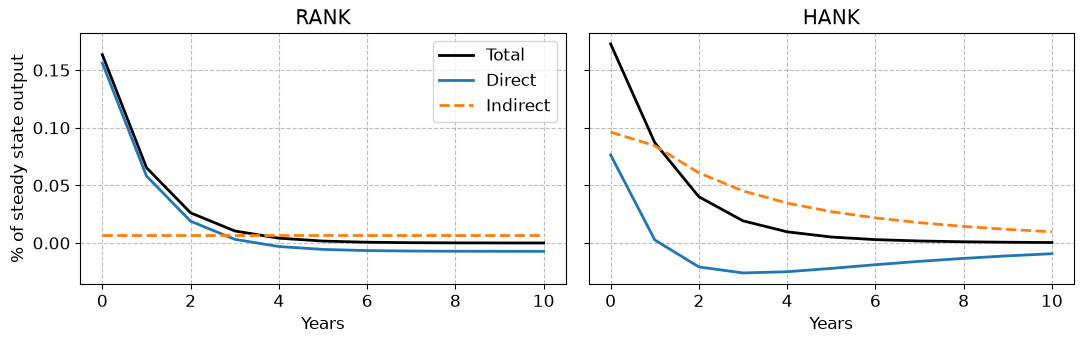

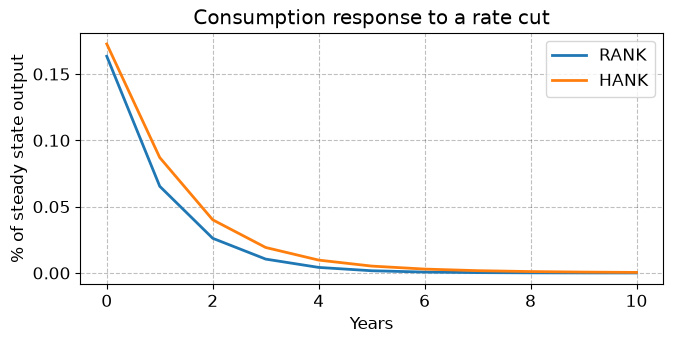

In [9]:
direct = M_r@dr
indirect = M@(dY-dT)

print(f'direct share of the impact response: HANK {direct[0]/dY[0]:.2f}')
print(f'impact response, % of Y: RANK {100*dC_RA[0]:.3f}, HANK {100*dY[0]:.3f}')

fig, axes = plt.subplots(1,2,figsize=(11,3.6),sharey=True)
for ax, total, direct_case, indirect_case, title in zip(axes,[dC_RA,dY],[direct_RA,direct],[indirect_RA,indirect],['RANK','HANK']):
    ax.plot(years,100*total[:T_plot],color='black',label='Total')
    ax.plot(years,100*direct_case[:T_plot],label='Direct')
    ax.plot(years,100*indirect_case[:T_plot],ls='--',label='Indirect')
    ax.set(xlabel='Years',title=title)
axes[0].set_ylabel('% of steady state output')
axes[0].legend()
fig.tight_layout()
fig.savefig('figs/mon_decomp_compare.pdf')

fig, ax = plt.subplots(figsize=(7,3.6))
ax.plot(years,100*dC_RA[:T_plot],label='RANK')
ax.plot(years,100*dY[:T_plot],label='HANK')
ax.set(xlabel='Years',ylabel='% of steady state output',title='Consumption response to a rate cut')
ax.legend()
fig.tight_layout()
fig.savefig('figs/mon_total_compare.pdf')

## 4. Generalized model: unequal incidence

Income shares are $z_{it}^{1+\zeta\log(Z_t/Z_{ss})}/\mathbb{E}[\cdot]$; $\zeta=0.3$ is procyclical risk. Only $\boldsymbol{M}$ changes, and still $\boldsymbol{q}^{\prime}\tilde{\boldsymbol{M}}=\boldsymbol{q}^{\prime}$.

In [10]:
model_procyclical = HANKModel.HANKModelClass(name='procyclical',par={'zeta':0.3})
model_procyclical.find_ss()
model_procyclical.compute_jacs()
model_procyclical.find_IRFs(shocks=['eps_r'])

M_procyclical = model_procyclical.jac_hh[('C_hh','Z')]
M_r_procyclical = model_procyclical.jac_hh[('C_hh','ra')]@Lag
dY_procyclical = solve_IKC(M_procyclical,M_r_procyclical,dr,ss.B)

print(f'iMPC at impact {M_procyclical[0,0]:.3f}, dY_0 = {100*dY_procyclical[0]:.3f}%')
print(f'max |IKC - find_IRFs| = {np.max(np.abs(dY_procyclical-model_procyclical.IRF["Y"])):.1e}')
print(f"max |q'M - q'| = {np.max(np.abs(q@M_procyclical-q)[:100]):.1e}")

iMPC at impact 0.334, dY_0 = 0.161%
max |IKC - find_IRFs| = 2.0e-10
max |q'M - q'| = 2.4e-11


## 5. Forward guidance

### The puzzle in RANK

With a nominal cut, inflation lowers the real rate further. We solve backwards from the cut, with $dr_t=di_t-d\pi_{t+1}$ and the linearized W-NKPC $d\pi_t=\kappa_C\,dC_t+\beta\,d\pi_{t+1}$.

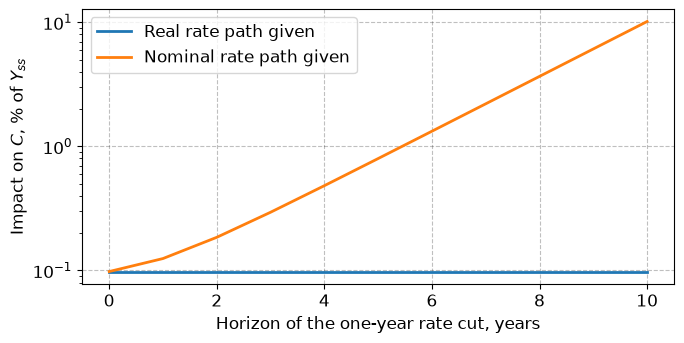

In [11]:
kappa_C = par.kappa*(1-ss.tau)*ss.C_hh**(-par.sigma)*(par.nu+par.sigma/ss.C_hh)
horizons = np.arange(21)

C0_nominal = np.zeros(len(horizons))
for h in horizons:

    dC = 0.0
    dpi = 0.0
    for t in reversed(range(h+1)):
        di = rate_cut if t == h else 0.0
        dC = dC - tilt*(di-dpi)
        dpi = kappa_C*dC + beta_RA*dpi

    C0_nominal[h] = dC

C0_real = np.full(len(horizons),-tilt*rate_cut)

fig, ax = plt.subplots(figsize=(7,3.6))
ax.plot(horizons[:T_plot],100*C0_real[:T_plot],label='Real rate path given')
ax.plot(horizons[:T_plot],100*C0_nominal[:T_plot],label='Nominal rate path given')
ax.set(yscale='log',xlabel='Horizon of the one-year rate cut, years',ylabel='Impact on $C$, % of $Y_{ss}$')
ax.legend()
fig.tight_layout()
fig.savefig('figs/fg_RANK.pdf')

### Werning: zero liquidity

We approximate zero liquidity with a tiny $B$, and scale the asset grid to it.

In [12]:
B_Werning = 1e-5
model_Werning = HANKModel.HANKModelClass(name='Werning',par={'B_target_ss':B_Werning,'a_max':300*B_Werning})
model_Werning.find_ss(do_print=True)
model_Werning.compute_jacs()

M_Werning = model_Werning.jac_hh[('C_hh','Z')]
M_r_Werning = model_Werning.jac_hh[('C_hh','ra')]@Lag

steady state found in 0.3 secs
 beta  =   0.6771
 tau   =   0.2000
 C     =   0.8000
Discrepancy in A =  -0.00000000
Discrepancy in Y =  -0.00000000


### HANK versus RANK

Impact of a one-year real rate cut at horizon $h$, relative to RANK.

HANK, acyclical risk: HANK/RANK at 0, 5, 10, 20 years = [1.09 0.93 0.84 0.68]
HANK, procyclical risk: HANK/RANK at 0, 5, 10, 20 years = [1.02 0.8  0.65 0.44]
HANK, zero liquidity (Werning): HANK/RANK at 0, 5, 10, 20 years = [1.   1.   0.99 0.99]


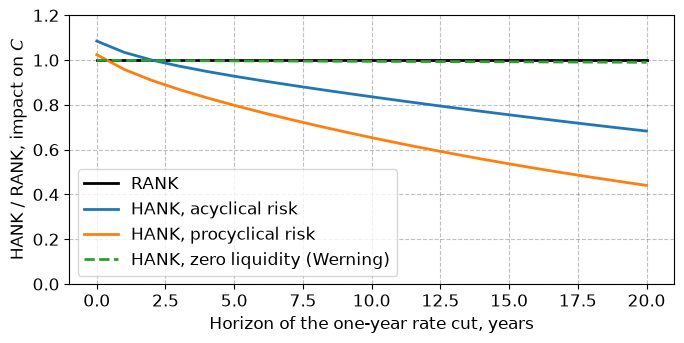

In [13]:
cases = [('HANK, acyclical risk',M,M_r,ss.B,'-'),
         ('HANK, procyclical risk',M_procyclical,M_r_procyclical,ss.B,'-'),
         ('HANK, zero liquidity (Werning)',M_Werning,M_r_Werning,B_Werning,'--')]

fig, ax = plt.subplots(figsize=(7,3.6))
ax.plot(horizons,np.ones(len(horizons)),color='black',label='RANK')

for label, M_case, M_r_case, B_case, linestyle in cases:

    ratio = np.zeros(len(horizons))
    for h in horizons:
        dr_h = np.zeros(T)
        dr_h[h] = rate_cut
        ratio[h] = solve_IKC(M_case,M_r_case,dr_h,B_case)[0]/C_RANK(dr_h)[0]

    ax.plot(horizons,ratio,ls=linestyle,label=label)
    print(f'{label}: HANK/RANK at 0, 5, 10, 20 years = {np.round(ratio[[0,5,10,20]],2)}')

ax.set(xlabel='Horizon of the one-year rate cut, years',ylabel='HANK / RANK, impact on $C$',ylim=(0,1.2))
ax.legend()
fig.tight_layout()
fig.savefig('figs/fg_HANK.pdf')